# COVID-19 Patients in Intensive Care: Country Analysis

This notebook analyses the daily count of COVID-19 patients in intensive care (ICU) for 42 countries and territories, from February 2020 to August 2024. The data comes from Our World in Data, which collated official hospital reports.

**Two limits shape everything below.** First, the series stops on 12 August 2024, so this is a historical analysis and not a picture of current hospital pressure. Second, reporting is patchy: some countries report for a few months and others for several years. Each section shows coverage where it matters.

Several questions use the weekly confirmed-cases file as well. Place `weekly-covid-cases.csv` in `data/raw/` alongside the ICU file. Its `Weekly cases` column is a rolling seven-day total, so the notebook divides by 7 to get a daily average.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
sns.set_palette("colorblind")
FIG = "figures/"


## 0. Loading and checking the data

I rename the columns, then check for duplicates, negative values, the date range, and how many days each country has. I also read the metadata file, which records when the series was last updated.

In [2]:
import json
icu_raw = pd.read_csv("data/raw/current-covid-patients-icu.csv", parse_dates=["Day"])
icu = icu_raw.rename(columns={"Entity": "entity", "Code": "code", "Day": "date",
                              "Current number of COVID-19 patients in ICU": "icu"})
meta = json.load(open("data/raw/current-covid-patients-icu_metadata.json"))

print("Rows:", f"{len(icu):,}", "| countries:", icu["entity"].nunique())
print("Date range:", icu["date"].min().date(), "to", icu["date"].max().date())
print("Duplicate entity-date pairs:", icu.duplicated(["entity", "date"]).sum())
print("Negative values:", (icu["icu"] < 0).sum(), "| zero values:", (icu["icu"] == 0).sum())
print("Metadata says last updated:", meta["columns"]["Daily ICU occupancy"]["lastUpdated"])
print("Metadata note:", meta["columns"]["Daily ICU occupancy"]["descriptionKey"].split(chr(10))[1].strip("- "))


Rows: 39,116 | countries: 42
Date range: 2020-02-24 to 2024-08-12
Duplicate entity-date pairs: 0
Negative values: 0 | zero values: 1045
Metadata says last updated: 2024-08-13
Metadata note: Hospital and ICU data are sourced from official providers and collated by Our World in Data, but no new datapoints have been added since 13 August 2024.


## 1. Which countries reached the highest ICU occupancy?

I take each country's highest daily count and the date it occurred. The axis is on a log scale because the United States is far above the others.

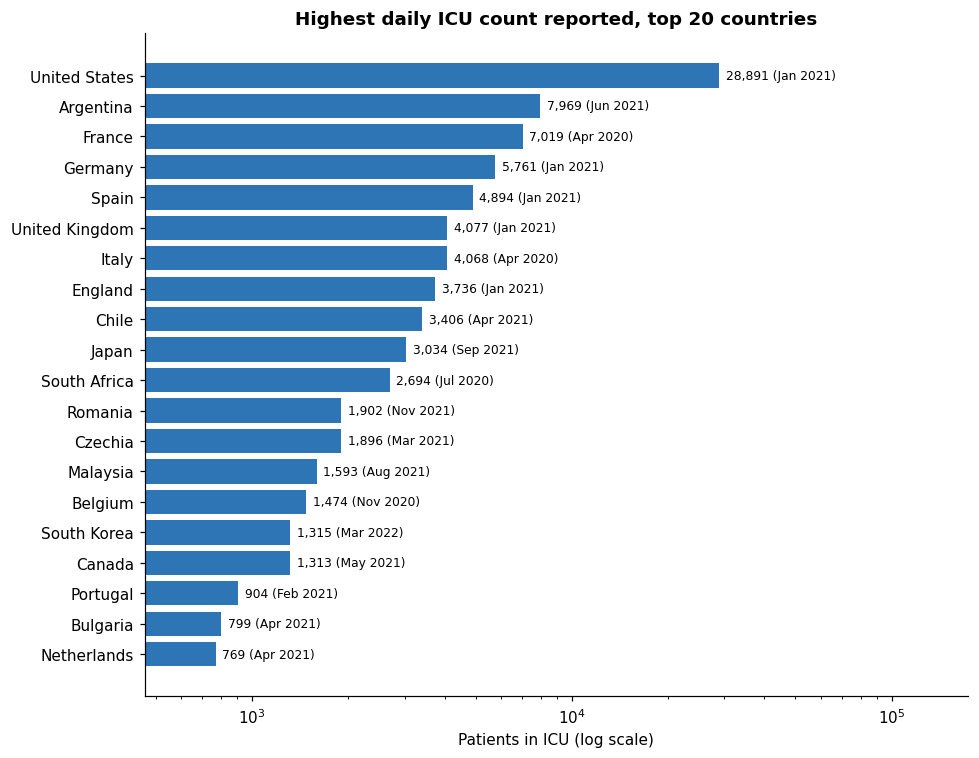

,entity,peak_date,peak_icu
0,United States,2021-01-12,28891
1,Argentina,2021-06-14,7969
2,France,2020-04-08,7019
3,Germany,2021-01-03,5761
4,Spain,2021-01-31,4894
5,United Kingdom,2021-01-24,4077
6,Italy,2020-04-03,4068
7,England,2021-01-24,3736
8,Chile,2021-04-27,3406
9,Japan,2021-09-01,3034


In [3]:
peak = (icu.loc[icu.groupby("entity")["icu"].idxmax(), ["entity", "date", "icu"]]
        .rename(columns={"date": "peak_date", "icu": "peak_icu"})
        .sort_values("peak_icu", ascending=False).reset_index(drop=True))

top = peak.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["entity"], top["peak_icu"], color="#2e75b6")
for i, (v, d) in enumerate(zip(top["peak_icu"], top["peak_date"])):
    ax.text(v * 1.05, i, f"{v:,.0f} ({d:%b %Y})", va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlim(top["peak_icu"].min() * 0.6, top["peak_icu"].max() * 6)
ax.set_title("Highest daily ICU count reported, top 20 countries")
ax.set_xlabel("Patients in ICU (log scale)")
plt.tight_layout(); plt.savefig(FIG + "01_peak_icu.png"); plt.show()

peak.head(10)


## 2. How complete is each country's record?

For each country I compare the number of days with a record to the number of days between its first and last record. A score near 100 percent means the country reported almost every day it could have. Low scores mean the series has gaps and should be read with care.

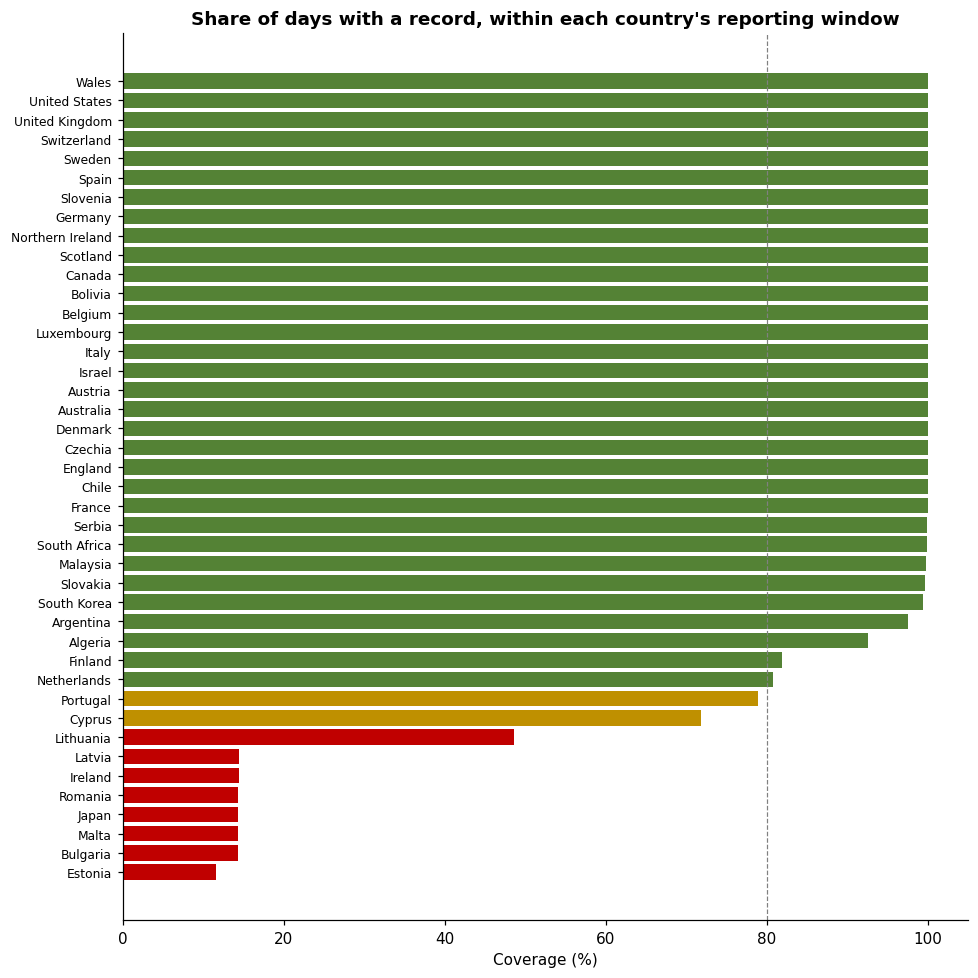

,first,last,count,coverage_pct
entity,,,,
Scotland,2020-03-18,2023-05-08,1147,100.0
Northern Ireland,2020-03-23,2022-05-22,791,100.0
Germany,2020-03-20,2023-06-26,1194,100.0
France,2020-03-18,2023-03-31,1109,100.0
England,2020-04-02,2023-05-31,1155,100.0
Chile,2020-04-01,2023-08-31,1248,100.0
Australia,2020-03-31,2023-12-07,1347,100.0
Denmark,2020-02-24,2023-06-12,1205,100.0
Austria,2020-04-01,2023-06-30,1186,100.0


In [4]:
span = icu.groupby("entity")["date"].agg(["min", "max", "count"])
span["days_in_window"] = (span["max"] - span["min"]).dt.days + 1
span["coverage_pct"] = (span["count"] / span["days_in_window"] * 100).round(1)
span = span.sort_values("coverage_pct")

fig, ax = plt.subplots(figsize=(9, 9))
colors = ["#c00000" if v < 50 else "#bf9000" if v < 80 else "#548235" for v in span["coverage_pct"]]
ax.barh(span.index, span["coverage_pct"], color=colors)
ax.axvline(80, color="grey", linestyle="--", linewidth=0.8)
ax.set_title("Share of days with a record, within each country's reporting window")
ax.set_xlabel("Coverage (%)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG + "02_coverage.png"); plt.show()

span[["min", "max", "count", "coverage_pct"]].rename(columns={"min": "first", "max": "last"}).sort_values("coverage_pct", ascending=False).head(10)


## 3. How did ICU occupancy move in ten selected countries?

The metadata file names ten countries for the original chart. I smooth each series with a 7-day average and plot each on its own scale, so that a country's wave shape is visible even when its numbers are much smaller than another's.

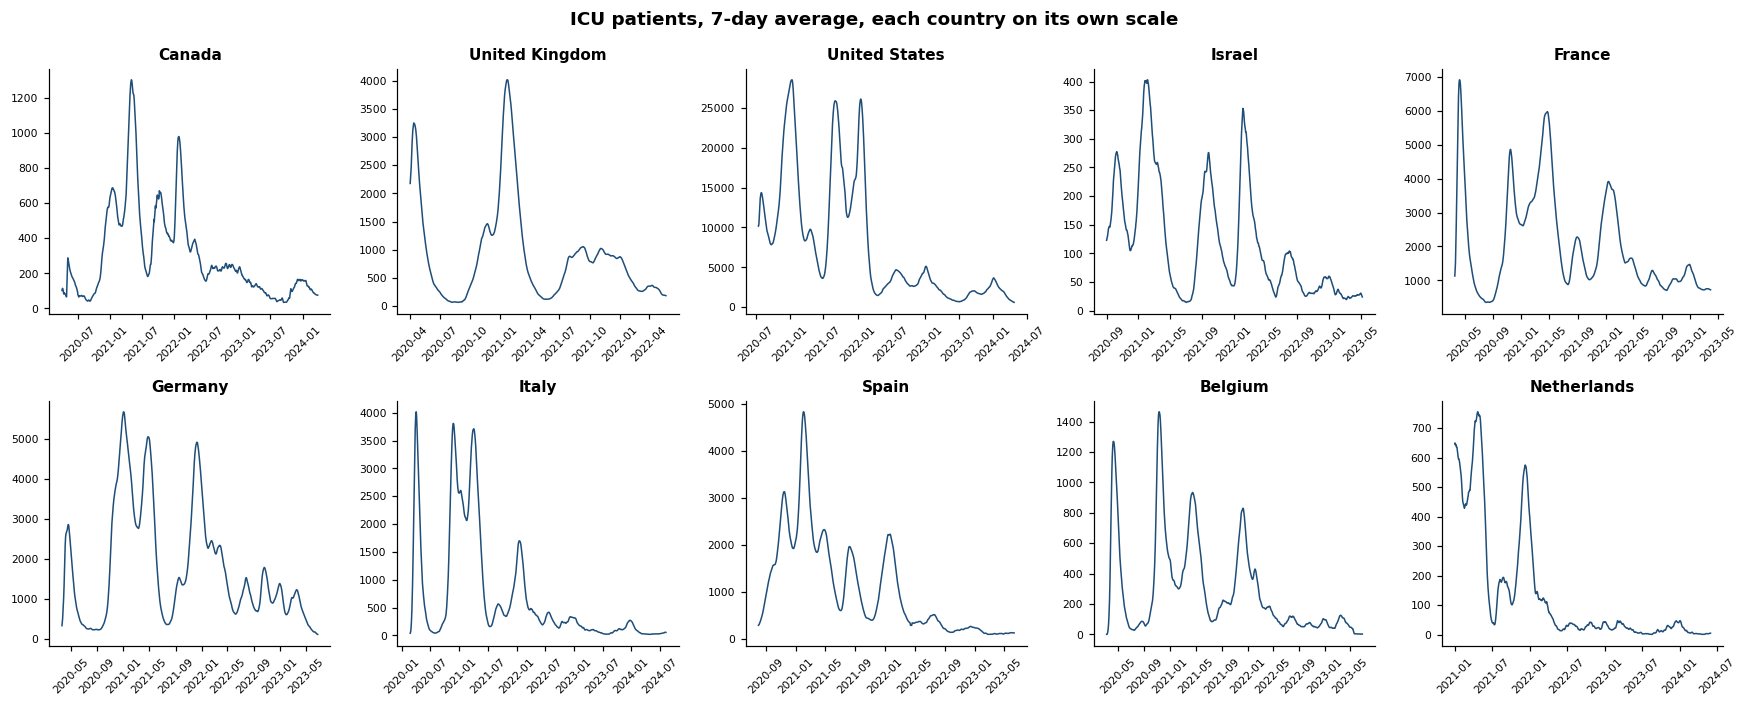

In [5]:
sel = meta["chart"]["selection"]
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharex=False)
for ax, c in zip(axes.ravel(), sel):
    s_c = icu[icu.entity == c].set_index("date")["icu"].sort_index()
    sm = s_c.asfreq("D").interpolate(limit=14).rolling(7, min_periods=3, center=True).mean()
    ax.plot(sm.index, sm.values, color="#1f4e79", linewidth=1)
    ax.set_title(c, fontsize=10)
    ax.tick_params(axis="x", labelsize=7, rotation=45)
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle("ICU patients, 7-day average, each country on its own scale", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG + "03_selected_countries.png"); plt.show()


## 4. How many countries were reporting in each month?

The number of reporting countries changes over time. If it falls in a particular period, any global total for that period would be built from fewer countries and would look smaller than it really was.

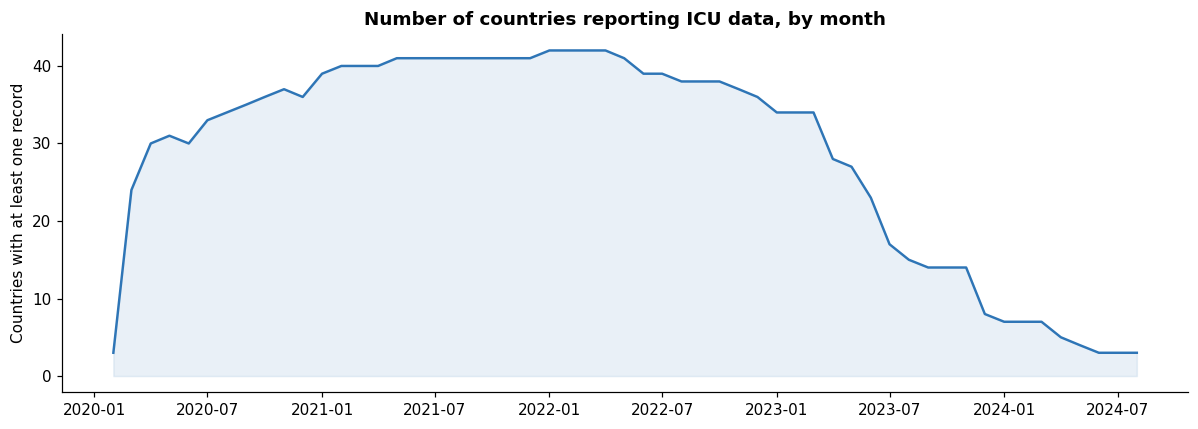

Most countries in a single month: 42 in January 2022
Countries reporting in the final month: 3


In [6]:
per_month = icu.groupby(icu["date"].dt.to_period("M"))["entity"].nunique()
per_month.index = per_month.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(per_month.index, per_month.values, color="#2e75b6", linewidth=1.6)
ax.fill_between(per_month.index, per_month.values, color="#2e75b6", alpha=0.1)
ax.set_title("Number of countries reporting ICU data, by month")
ax.set_ylabel("Countries with at least one record")
plt.tight_layout(); plt.savefig(FIG + "04_reporting_by_month.png"); plt.show()

print("Most countries in a single month:", per_month.max(), "in", per_month.idxmax().strftime("%B %Y"))
print("Countries reporting in the final month:", per_month.iloc[-1])


## 5. How many separate waves did each country show?

I smooth each series with a 14-day average. A peak only counts if it stands out by at least 15 percent of the country's maximum, and it has to be at least 60 days after the previous peak. Peak counts depend on these thresholds, so I use them as a rough guide.

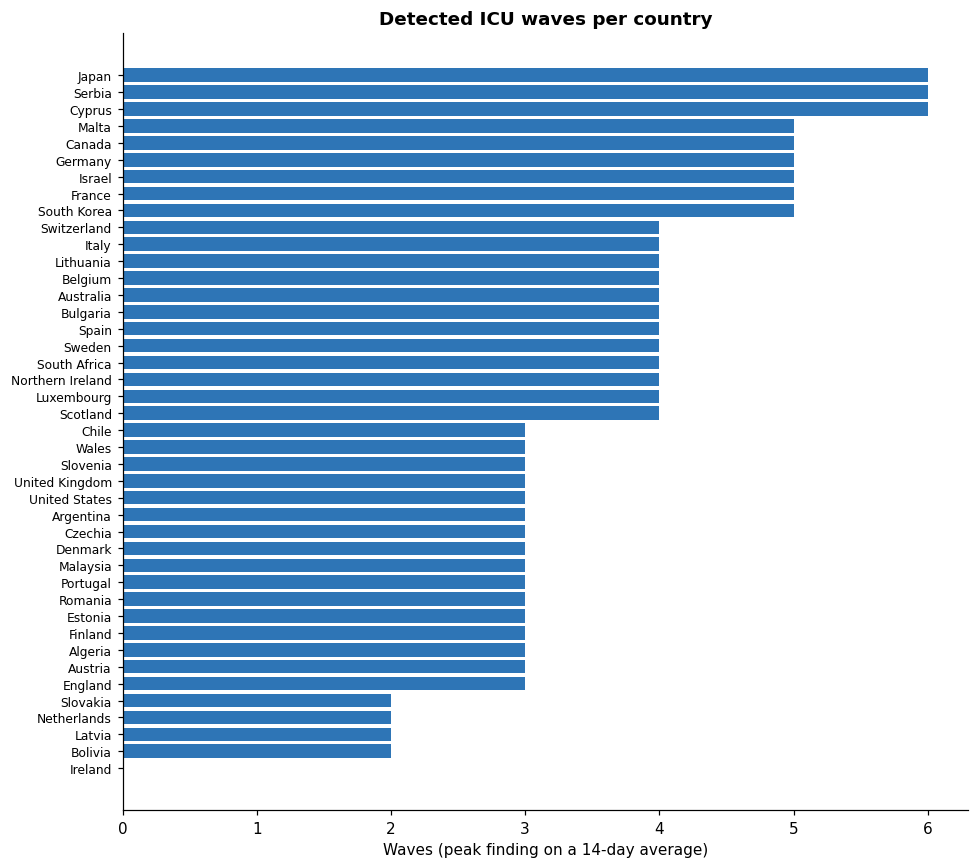

,waves,days_reported
country,,
Serbia,6,1194
Cyprus,6,818
Japan,6,203
France,5,1109
Germany,5,1194
South Korea,5,1066
Canada,5,1456
Israel,5,979
Malta,5,195


In [7]:
rows = []
for c, g in icu.groupby("entity"):
    a = g.set_index("date")["icu"].sort_index().asfreq("D")
    sm = a.interpolate(limit=14).rolling(14, min_periods=5, center=True).mean().fillna(0)
    if sm.max() <= 0:
        continue
    idx, _ = find_peaks(sm.values, prominence=sm.max() * 0.15, distance=60)
    rows.append({"country": c, "waves": len(idx), "days_reported": int(g.shape[0])})
waves = pd.DataFrame(rows).set_index("country").sort_values("waves")

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(waves.index, waves["waves"], color="#2e75b6")
ax.set_title("Detected ICU waves per country")
ax.set_xlabel("Waves (peak finding on a 14-day average)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG + "05_waves.png"); plt.show()

waves.sort_values("waves", ascending=False).head(10)


## 6. When did each country reach its main ICU peak?

I find the date of each country's largest 14-day average and plot the dates on a timeline. The spread of dates shows how far apart national waves were, which is useful when reading global totals.

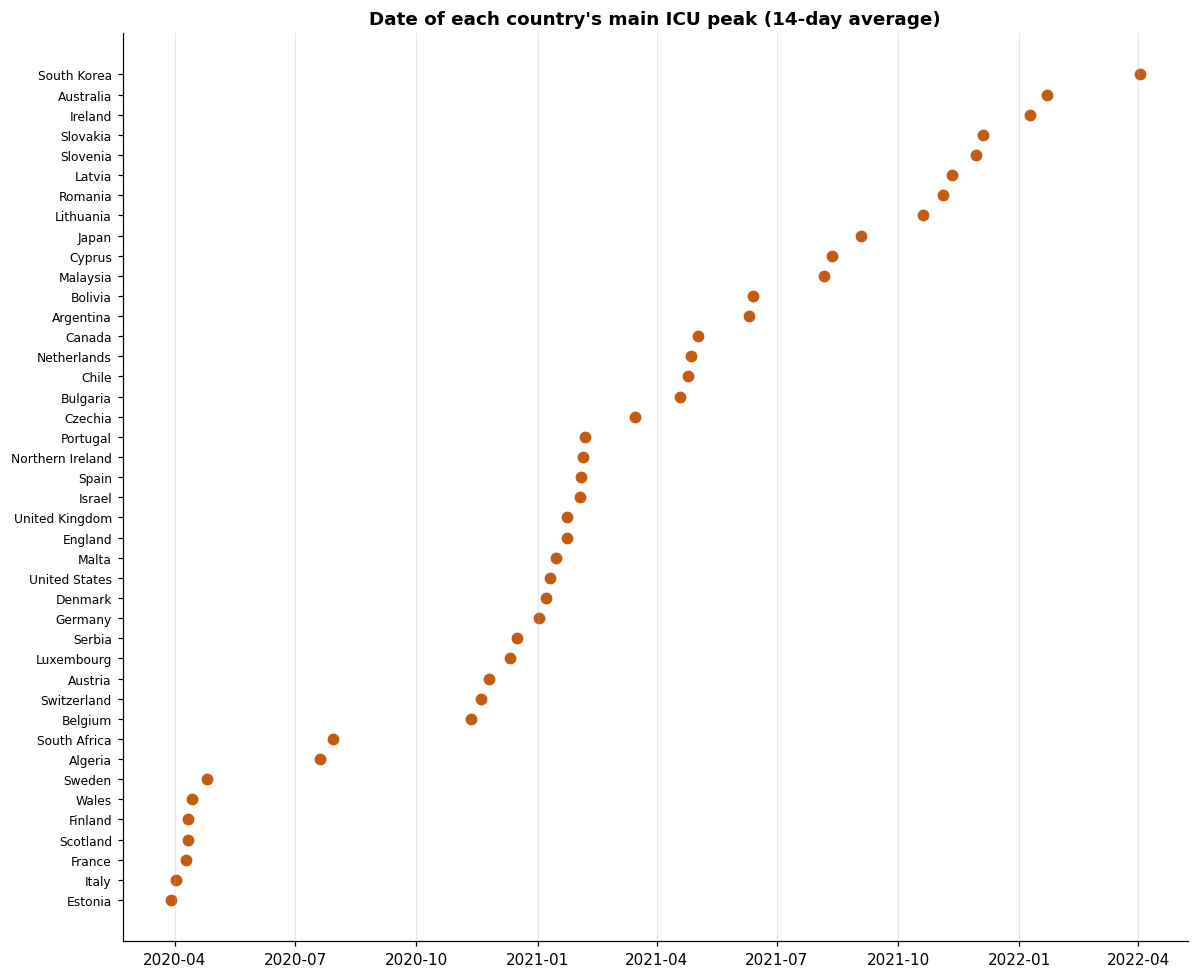

Earliest main peak: Estonia 2020-03-29
Latest main peak: South Korea 2022-04-02


In [8]:
main = []
for c, g in icu.groupby("entity"):
    a = g.set_index("date")["icu"].sort_index().asfreq("D")
    sm = a.interpolate(limit=14).rolling(14, min_periods=5, center=True).mean()
    if sm.notna().sum() == 0:
        continue
    main.append({"country": c, "main_peak_date": sm.idxmax(), "peak_avg": sm.max()})
main = pd.DataFrame(main).sort_values("main_peak_date").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(main["main_peak_date"], main["country"], s=45, color="#c55a11")
ax.set_title("Date of each country's main ICU peak (14-day average)")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig(FIG + "06_main_peak_timeline.png"); plt.show()

print("Earliest main peak:", main.iloc[0]["country"], main.iloc[0]["main_peak_date"].date())
print("Latest main peak:", main.iloc[-1]["country"], main.iloc[-1]["main_peak_date"].date())


## 7. A month-by-month view of each country's waves

Each row is scaled to its own maximum, so a value of 1.0 marks that country's worst month. Countries are sorted by the date of their main peak. The diagonal pattern shows how the waves travelled through time.

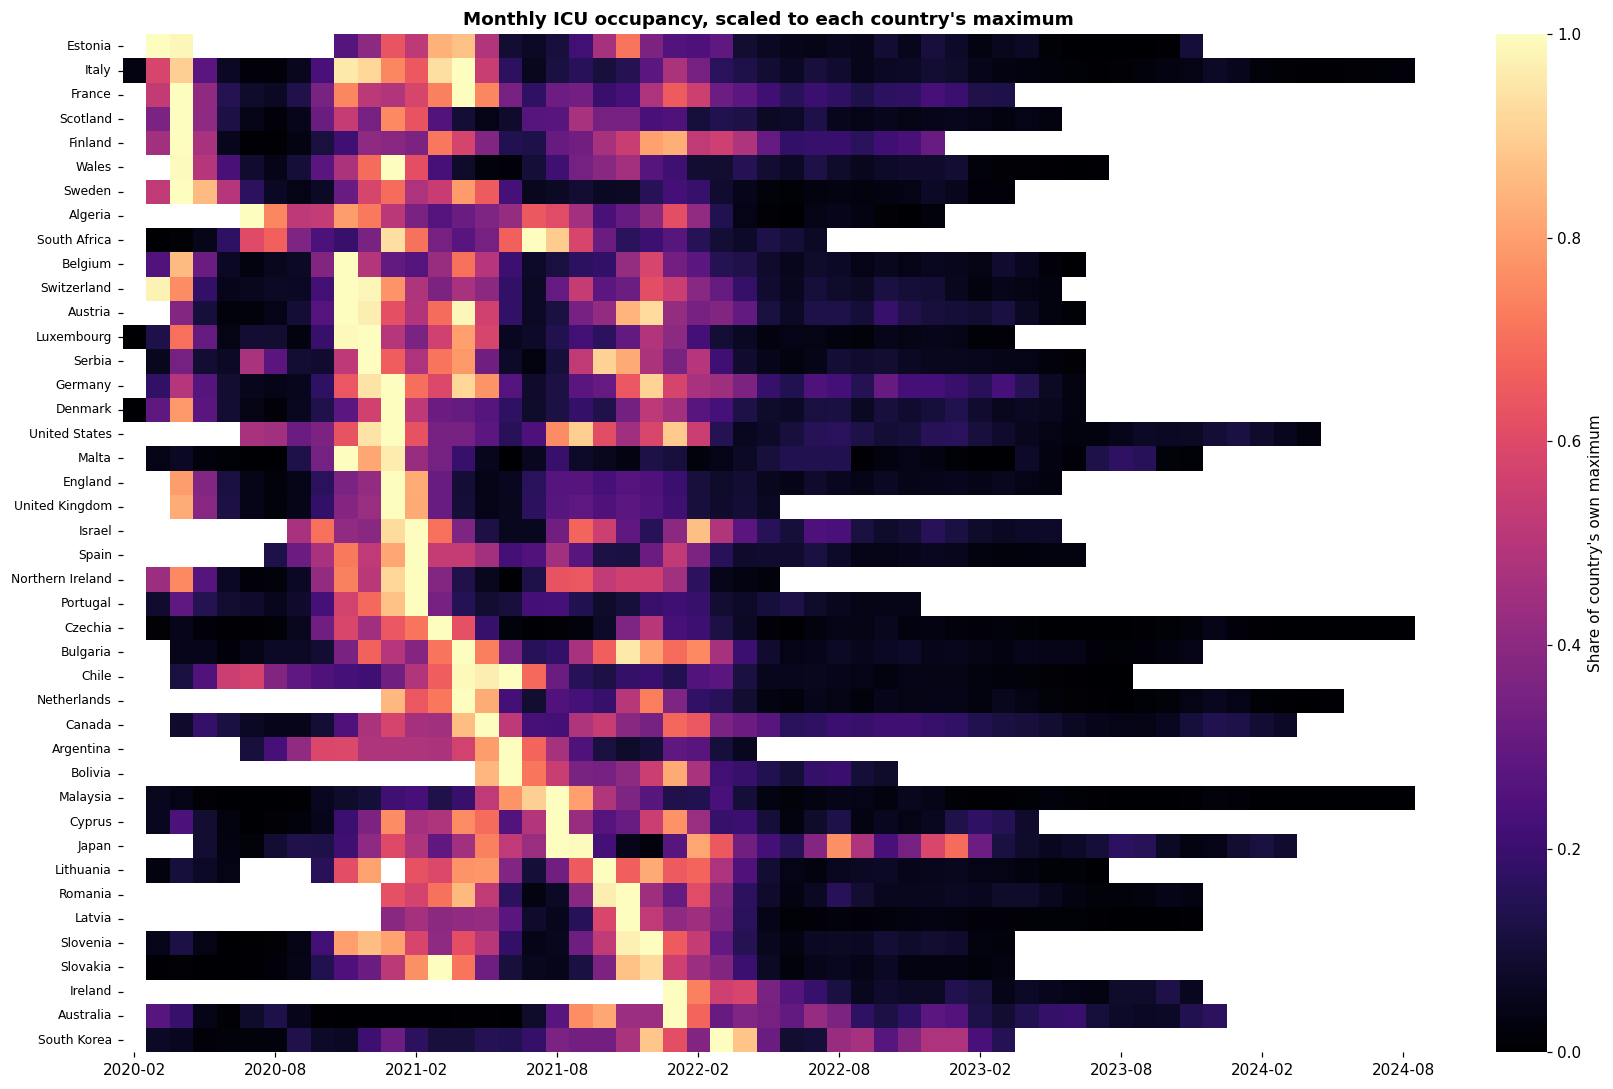

In [9]:
rows = {}
for c, g in icu.groupby("entity"):
    a = g.set_index("date")["icu"].sort_index().asfreq("D")
    sm = a.interpolate(limit=14).rolling(14, min_periods=5, center=True).mean()
    m = sm.resample("MS").mean()
    if m.max() > 0:
        rows[c] = (m / m.max()).rename(lambda d: d.strftime("%Y-%m"))
mat = pd.DataFrame(rows).T
order = main.set_index("country").loc[[c for c in main["country"] if c in mat.index]].index
mat = mat.loc[order]

fig, ax = plt.subplots(figsize=(16, 10))
sns.heatmap(mat, cmap="magma", ax=ax, cbar_kws={"label": "Share of country's own maximum"},
            xticklabels=6, yticklabels=True)
ax.set_title("Monthly ICU occupancy, scaled to each country's maximum")
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG + "07_monthly_heatmap.png"); plt.show()


## 8. Did later waves put fewer people in ICU than earlier ones?

I compare each country's average ICU count in 2020 and 2021 with its average in 2022 and 2023. A ratio below 1 means the later period had lower average occupancy. Many countries have gaps in one period, so I only include countries with enough records in both.

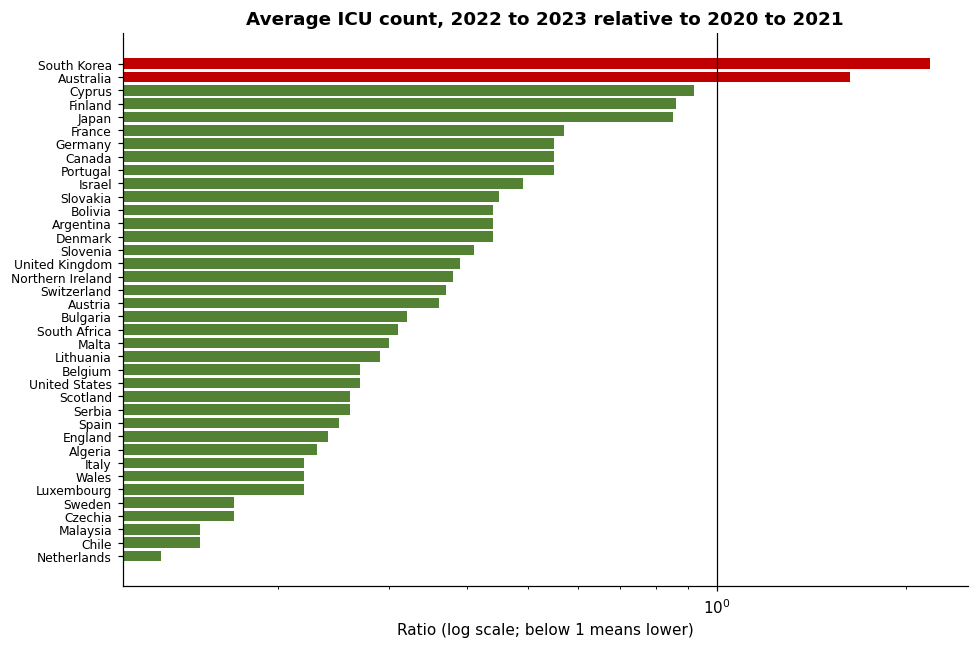

,mean_2020_21,mean_2022_23,ratio_late_to_early
country,,,
Netherlands,371.9,48.5,0.13
Chile,1358.4,203.3,0.15
Malaysia,429.6,63.1,0.15
Czechia,442.9,73.3,0.17
Sweden,169.4,28.8,0.17
Luxembourg,14.3,3.1,0.22
Wales,45.7,10.1,0.22
Italy,1331.0,298.4,0.22
Algeria,30.1,7.0,0.23


In [10]:
def period_mean(g, years):
    x = g[g.date.dt.year.isin(years)]
    return x["icu"].mean(), len(x)

rows = []
for c, g in icu.groupby("entity"):
    m1, n1 = period_mean(g, [2020, 2021])
    m2, n2 = period_mean(g, [2022, 2023])
    if n1 >= 60 and n2 >= 60 and m1 > 0:
        rows.append({"country": c, "mean_2020_21": round(m1, 1), "mean_2022_23": round(m2, 1),
                     "ratio_late_to_early": round(m2 / m1, 2)})
ratio = pd.DataFrame(rows).set_index("country").sort_values("ratio_late_to_early")

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#548235" if v < 1 else "#c00000" for v in ratio["ratio_late_to_early"]]
ax.barh(ratio.index, ratio["ratio_late_to_early"], color=colors)
ax.axvline(1, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_title("Average ICU count, 2022 to 2023 relative to 2020 to 2021")
ax.set_xlabel("Ratio (log scale; below 1 means lower)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG + "08_early_vs_late.png"); plt.show()

ratio


## 9. Do ICU records look different on weekends?

Hospitals sometimes report less on weekends, and the count can be carried forward. I compare the average on Saturdays and Sundays with the average on weekdays, for countries with at least 200 records. A ratio far from 1 can be a real pattern in hospital admissions, but it can also be a reporting pattern.

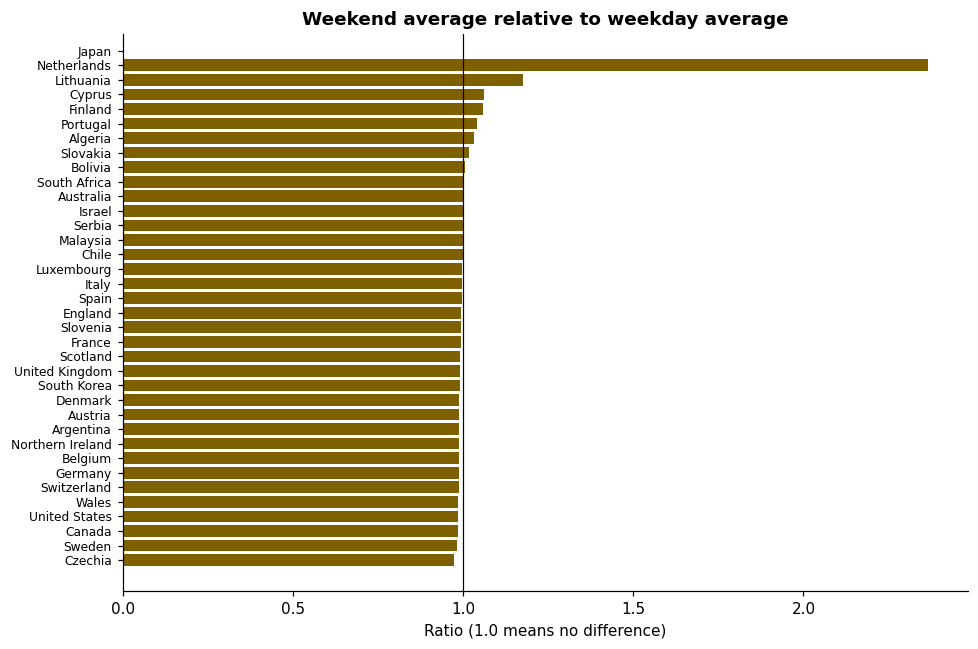

Share of all records falling on weekends: 29.5 %


,weekend_share_of_records,weekend_to_weekday_ratio
country,,
Czechia,28.6,0.973
Sweden,28.6,0.982
Canada,28.6,0.984
United States,28.5,0.985
Wales,28.5,0.986
Switzerland,28.5,0.987
Germany,28.6,0.987
Belgium,28.6,0.987


In [11]:
d = icu.assign(weekend=icu.date.dt.dayofweek >= 5)
rows = []
for c, g in d.groupby("entity"):
    if len(g) < 200:
        continue
    wk = g.loc[g.weekend, "icu"].mean()
    wd = g.loc[~g.weekend, "icu"].mean()
    if wd and wd > 0:
        rows.append({"country": c, "weekend_share_of_records": round(g.weekend.mean() * 100, 1),
                     "weekend_to_weekday_ratio": round(wk / wd, 3)})
wk_tbl = pd.DataFrame(rows).set_index("country").sort_values("weekend_to_weekday_ratio")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(wk_tbl.index, wk_tbl["weekend_to_weekday_ratio"], color="#7f6000")
ax.axvline(1, color="black", linewidth=0.8)
ax.set_title("Weekend average relative to weekday average")
ax.set_xlabel("Ratio (1.0 means no difference)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG + "09_weekend_effect.png"); plt.show()

print("Share of all records falling on weekends:", round(d.weekend.mean() * 100, 1), "%")
wk_tbl.head(8)


## 10. How often is the count recorded as zero?

There are over a thousand zero values in this file. A zero can be a real low point in a quiet period, or it can mean the country did not report that day. I count zeros by country and show each country's share of records.

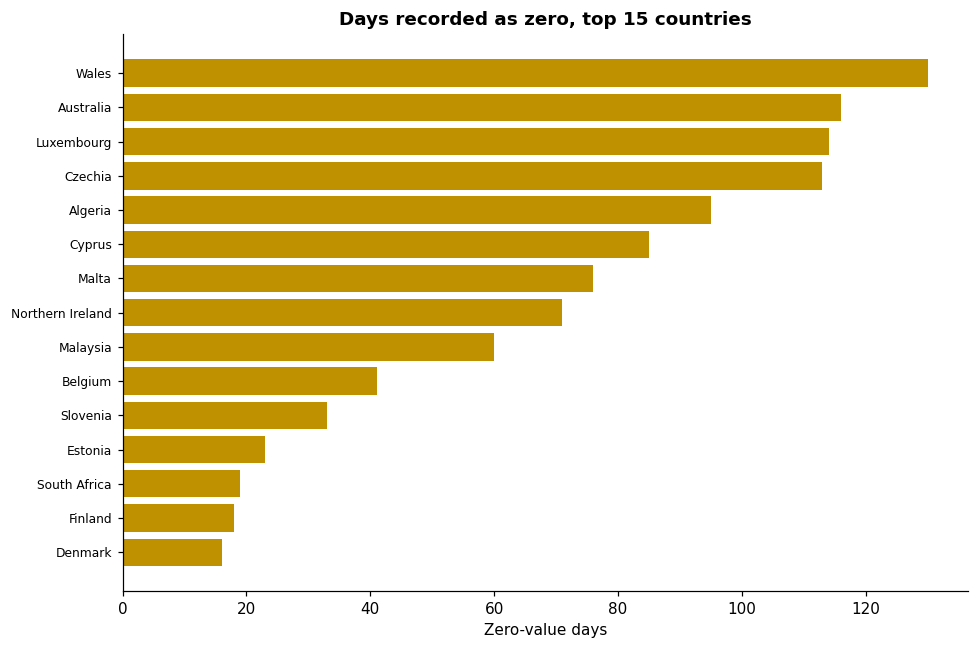

,zero_days,share_zero
entity,,
Wales,130,10.9
Australia,116,8.6
Luxembourg,114,10.1
Czechia,113,6.9
Algeria,95,11.5
Cyprus,85,10.4
Malta,76,39.0
Northern Ireland,71,9.0
Malaysia,60,3.8


In [12]:
zeros = icu.assign(is_zero=icu["icu"] == 0).groupby("entity")["is_zero"].agg(["sum", "mean"])
zeros.columns = ["zero_days", "share_zero"]
zeros["share_zero"] = (zeros["share_zero"] * 100).round(1)
zt = zeros.sort_values("zero_days", ascending=False).head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(zt.index, zt["zero_days"], color="#bf9000")
ax.set_title("Days recorded as zero, top 15 countries")
ax.set_xlabel("Zero-value days")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG + "10_zeros.png"); plt.show()

zeros.sort_values("zero_days", ascending=False).head(10)


## 11. How spread out are ICU counts within each country?

For each country, I show the distribution of its daily counts. Counts are shown on a log scale. Countries with very wide boxes had large swings between quiet and busy periods.

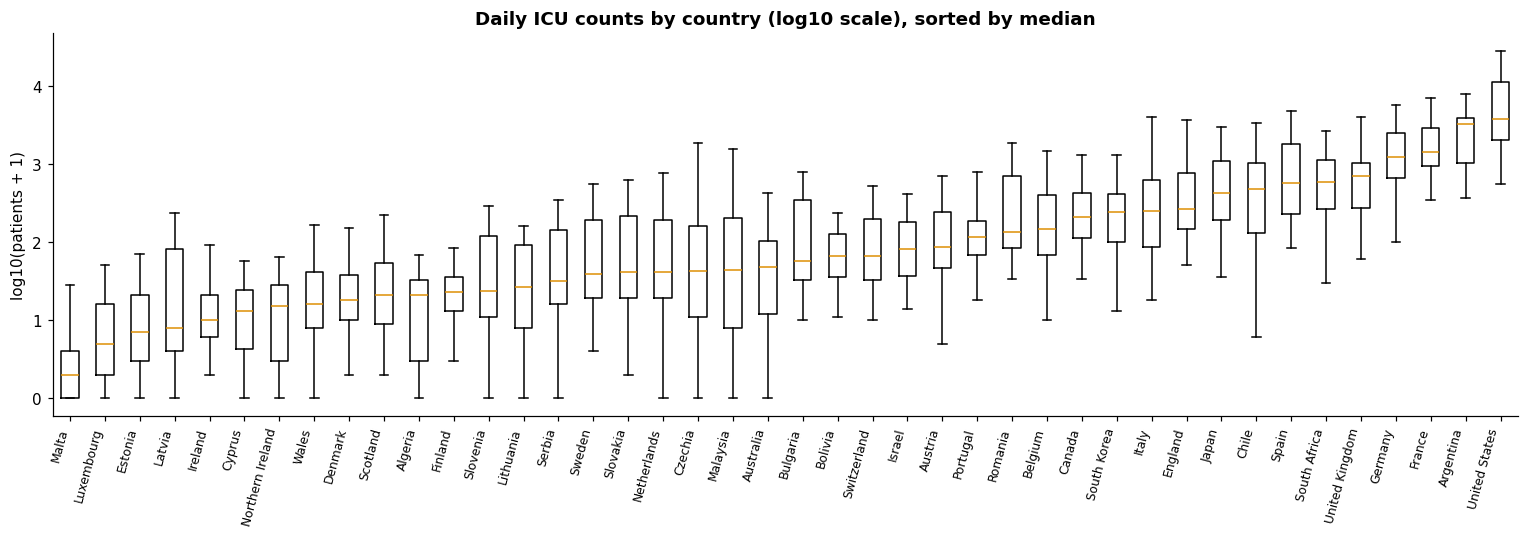

In [13]:
order = icu.groupby("entity")["icu"].median().sort_values().index
data = [np.log10(icu.loc[icu.entity == c, "icu"].values + 1) for c in order]

fig, ax = plt.subplots(figsize=(14, 5))
ax.boxplot(data, tick_labels=order, showfliers=False)
ax.set_title("Daily ICU counts by country (log10 scale), sorted by median")
ax.set_ylabel("log10(patients + 1)")
plt.setp(ax.get_xticklabels(), rotation=75, ha="right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "11_distribution.png"); plt.show()


## 12. What are the longest gaps between records?

A long gap in a series means the country stopped reporting for a while. I measure the longest stretch between two consecutive records for each country.

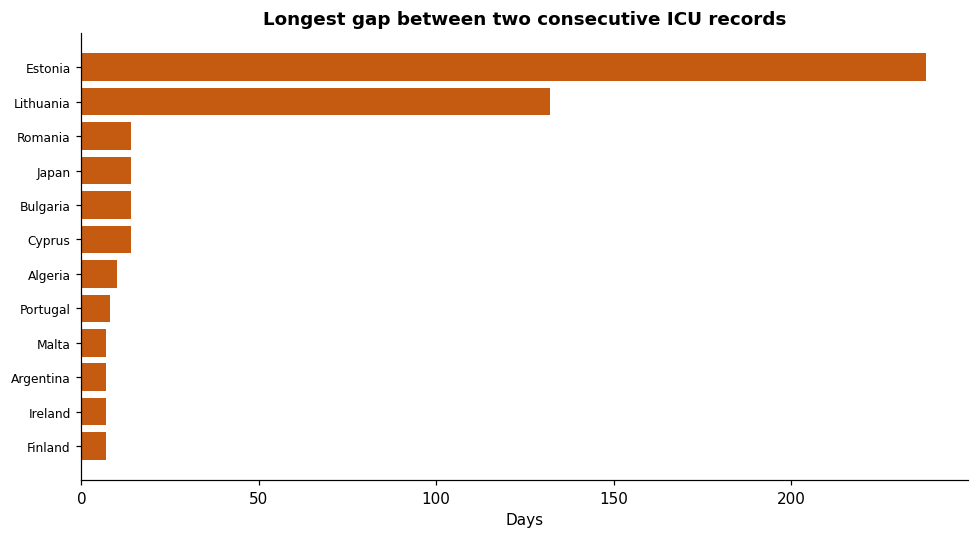

,longest_gap_days
entity,
Estonia,238.0
Lithuania,132.0
Romania,14.0
Japan,14.0
Bulgaria,14.0
Cyprus,14.0
Algeria,10.0
Portugal,8.0
Malta,7.0


In [14]:
gaps = icu.sort_values(["entity", "date"]).groupby("entity")["date"].apply(lambda s: s.diff().dt.days.max())
gaps = gaps.rename("longest_gap_days").sort_values(ascending=False).head(12).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(gaps.index, gaps.values, color="#c55a11")
ax.set_title("Longest gap between two consecutive ICU records")
ax.set_xlabel("Days")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG + "12_gaps.png"); plt.show()

gaps.iloc[::-1].to_frame()


## 13. Do ICU counts follow case counts, and with what delay?

This question uses both files. For each country present in both, I correlate the seven-day case average with the seven-day ICU average. I shift the case series forward by 0 to 42 days and find the lag that gives the strongest correlation. A positive best lag means cases came first.

Correlations between two rising waves can be high for reasons unrelated to lag. Read the lag as a pattern in this data, not as proof of a causal delay.

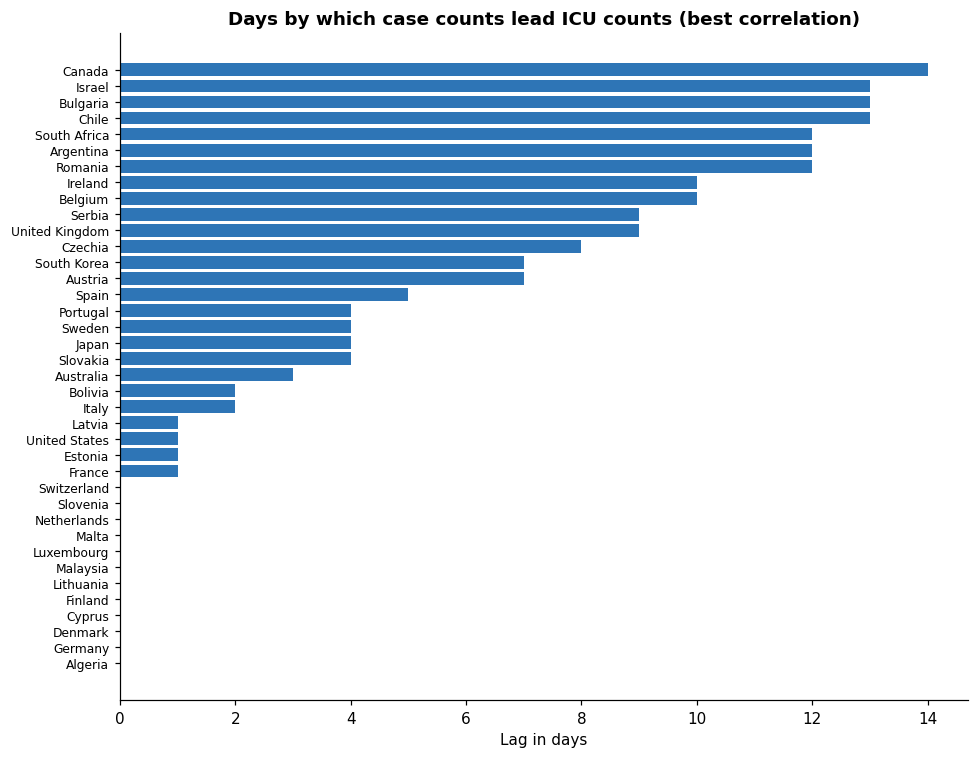

Median best lag: 3.5 days across 38 countries


,best_lag_days,correlation_at_lag
country,,
Algeria,0,0.720
Germany,0,0.156
Denmark,0,0.159
Cyprus,0,0.204
Finland,0,0.416
Lithuania,0,0.467
Malaysia,0,0.665
Luxembourg,0,0.020
Malta,0,0.188


In [15]:
cases = pd.read_csv("data/raw/weekly-covid-cases.csv", parse_dates=["Day"]).rename(
    columns={"Entity": "entity", "Day": "date", "Weekly cases": "weekly"})
cases["avg"] = cases["weekly"] / 7

rows = []
for c in icu["entity"].unique():
    a = icu[icu.entity == c].set_index("date")["icu"].sort_index().asfreq("D")
    a7 = a.interpolate(limit=7).rolling(7, min_periods=4, center=True).mean()
    b = cases[cases.entity == c].set_index("date")["avg"].sort_index().asfreq("D")
    if b.empty or a7.notna().sum() < 200:
        continue
    best_lag, best_r = None, -np.inf
    for lag in range(0, 43):
        pair = pd.concat([b.shift(lag), a7], axis=1).dropna()
        if len(pair) < 200 or pair.iloc[:, 0].std() == 0 or pair.iloc[:, 1].std() == 0:
            continue
        r = pair.corr().iloc[0, 1]
        if r > best_r:
            best_lag, best_r = lag, r
    if best_lag is not None:
        rows.append({"country": c, "best_lag_days": best_lag, "correlation_at_lag": round(best_r, 3)})
lags = pd.DataFrame(rows).set_index("country").sort_values("best_lag_days")

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(lags.index, lags["best_lag_days"], color="#2e75b6")
ax.set_title("Days by which case counts lead ICU counts (best correlation)")
ax.set_xlabel("Lag in days")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG + "13_lead_lag.png"); plt.show()

print("Median best lag:", lags["best_lag_days"].median(), "days across", len(lags), "countries")
lags


## 14. Does the ICU peak come after the case peak?

For each country, I find its main ICU peak. Then I take the highest case average within 120 days on either side of that date. Limiting the search this way keeps the comparison to the same wave. Without it, an early ICU peak could be paired with a much later case peak from a different wave, which would make the gap look larger than it is.

A positive number means the ICU peak came after the case peak. The 120-day window is a judgement call. Changing it would move some countries' results.

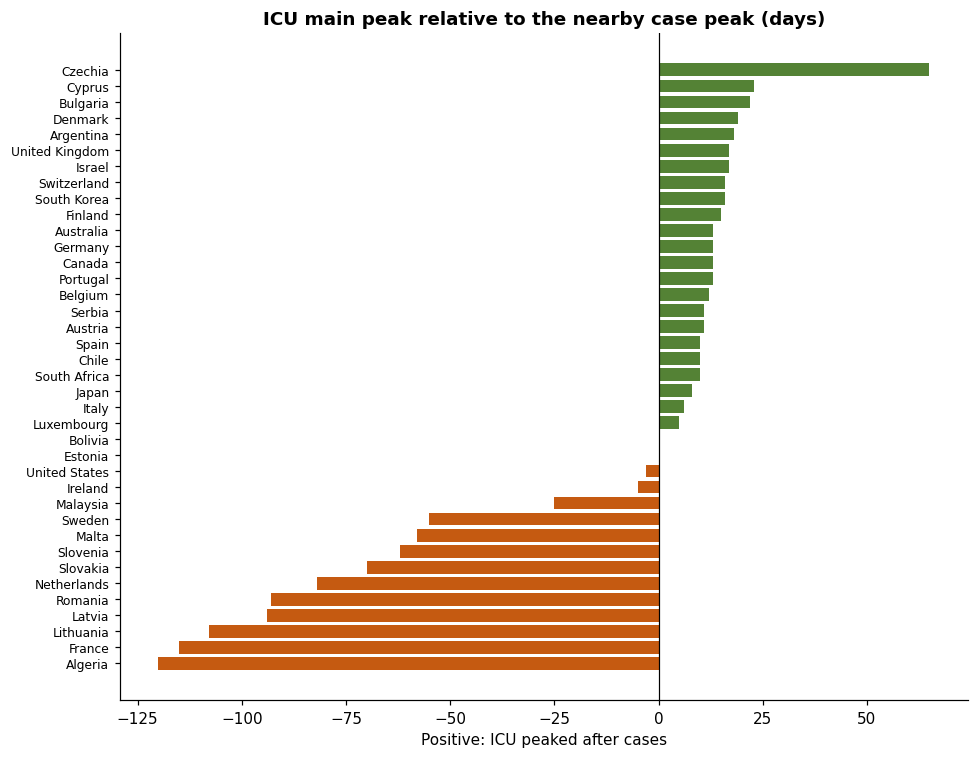

Countries where ICU peaked after cases: 23 of 38
Median offset: 10.0 days
Range: -120 to 65 days


,case_peak,icu_peak,icu_minus_case_days
country,,,
Algeria,2020-11-17,2020-07-20,-120
France,2020-08-02,2020-04-09,-115
Lithuania,2022-02-05,2021-10-20,-108
Latvia,2022-02-13,2021-11-11,-94
Romania,2022-02-05,2021-11-04,-93
Netherlands,2021-07-18,2021-04-27,-82
Slovakia,2022-02-12,2021-12-04,-70
Slovenia,2022-01-30,2021-11-29,-62
Malta,2021-03-14,2021-01-15,-58


In [16]:
rows = []
for c, g in icu.groupby("entity"):
    a = g.set_index("date")["icu"].sort_index().asfreq("D")
    sm = a.interpolate(limit=14).rolling(14, min_periods=5, center=True).mean()
    if sm.notna().sum() == 0:
        continue
    icu_pk = sm.idxmax()
    win = cases[(cases.entity == c) & cases.date.between(icu_pk - pd.Timedelta(days=120),
                                                       icu_pk + pd.Timedelta(days=120))]
    if win.empty or win["avg"].max() <= 0:
        continue
    case_pk = win.loc[win["avg"].idxmax(), "date"]
    rows.append({"country": c, "case_peak": case_pk.date(), "icu_peak": icu_pk.date(),
                 "icu_minus_case_days": (icu_pk - case_pk).days})
pk = pd.DataFrame(rows).set_index("country").sort_values("icu_minus_case_days")

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#548235" if v >= 0 else "#c55a11" for v in pk["icu_minus_case_days"]]
ax.barh(pk.index, pk["icu_minus_case_days"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("ICU main peak relative to the nearby case peak (days)")
ax.set_xlabel("Positive: ICU peaked after cases")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG + "14_peak_offset.png"); plt.show()

print("Countries where ICU peaked after cases:", (pk["icu_minus_case_days"] > 0).sum(), "of", len(pk))
print("Median offset:", pk["icu_minus_case_days"].median(), "days")
print("Range:", pk["icu_minus_case_days"].min(), "to", pk["icu_minus_case_days"].max(), "days")
pk


## 15. How many ICU patients per 1,000 daily cases?

This is a rough severity indicator. At each country's ICU peak, I divide the ICU count by the daily case average from the best lag found in section 13, then multiply by 1,000. The result is the number of ICU patients for each 1,000 new cases a day.

The figure depends on testing levels, the age of cases, and how the country counts ICU patients. Treat differences between countries as a question for further study, not a ranking of care quality.

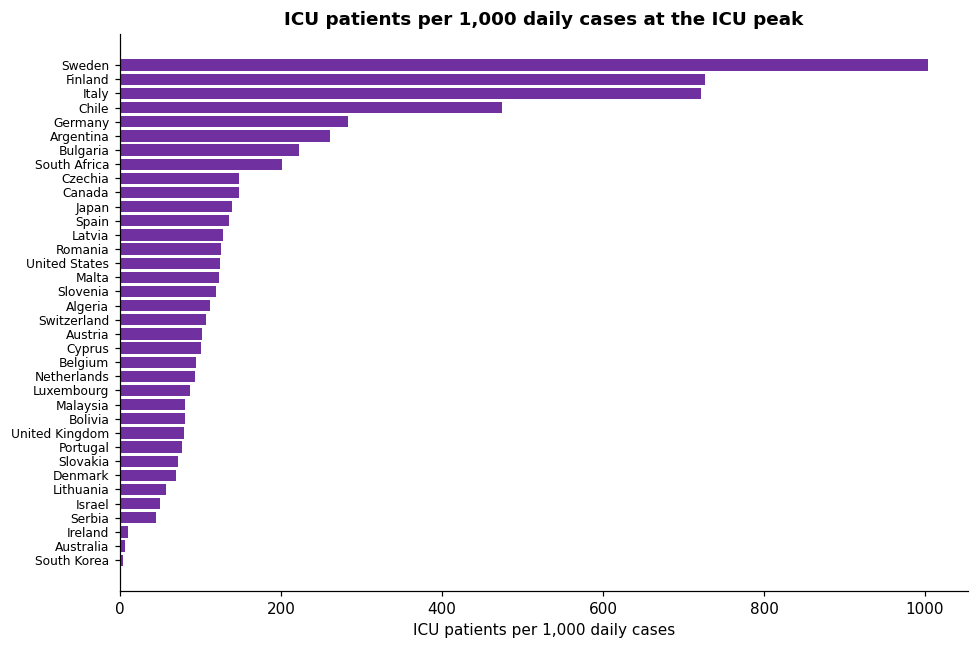

,icu_peak,cases_per_day_at_lag,icu_per_1000_cases
country,,,
Sweden,541.2,539.4,1003.31
Finland,77.7,106.9,727.27
Italy,3901.4,5401.7,722.26
Chile,3371.1,7102.0,474.68
Germany,5620.4,19832.6,283.39
Argentina,7803.4,29892.4,261.05
Bulgaria,779.9,3498.4,222.92
South Africa,2498.2,12415.3,201.22
Czechia,1831.0,12369.0,148.03


In [17]:
rows = []
for c in lags.index:
    g = icu[icu.entity == c].set_index("date")["icu"].sort_index().asfreq("D")
    sm = g.interpolate(limit=14).rolling(14, min_periods=5, center=True).mean()
    if sm.notna().sum() == 0:
        continue
    pk_date = sm.idxmax()
    lag = int(lags.loc[c, "best_lag_days"])
    case_date = pk_date - pd.Timedelta(days=lag)
    cb = cases[(cases.entity == c) & (cases.date == case_date)]["avg"]
    if cb.empty or cb.iloc[0] < 100:
        continue
    rows.append({"country": c, "icu_peak": round(sm.max(), 1), "cases_per_day_at_lag": round(cb.iloc[0], 1),
                 "icu_per_1000_cases": round(sm.max() / cb.iloc[0] * 1000, 2)})
sev = pd.DataFrame(rows).set_index("country").sort_values("icu_per_1000_cases")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(sev.index, sev["icu_per_1000_cases"], color="#7030a0")
ax.set_title("ICU patients per 1,000 daily cases at the ICU peak")
ax.set_xlabel("ICU patients per 1,000 daily cases")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG + "15_icu_per_1000_cases.png"); plt.show()

sev.sort_values("icu_per_1000_cases", ascending=False)


## 16. Which countries' ICU waves moved together?

I compare the seven-day ICU averages for 2021 and 2022, using countries with at least 60 percent coverage across those two years. High correlations suggest shared timing, usually from common variants or shared policy.

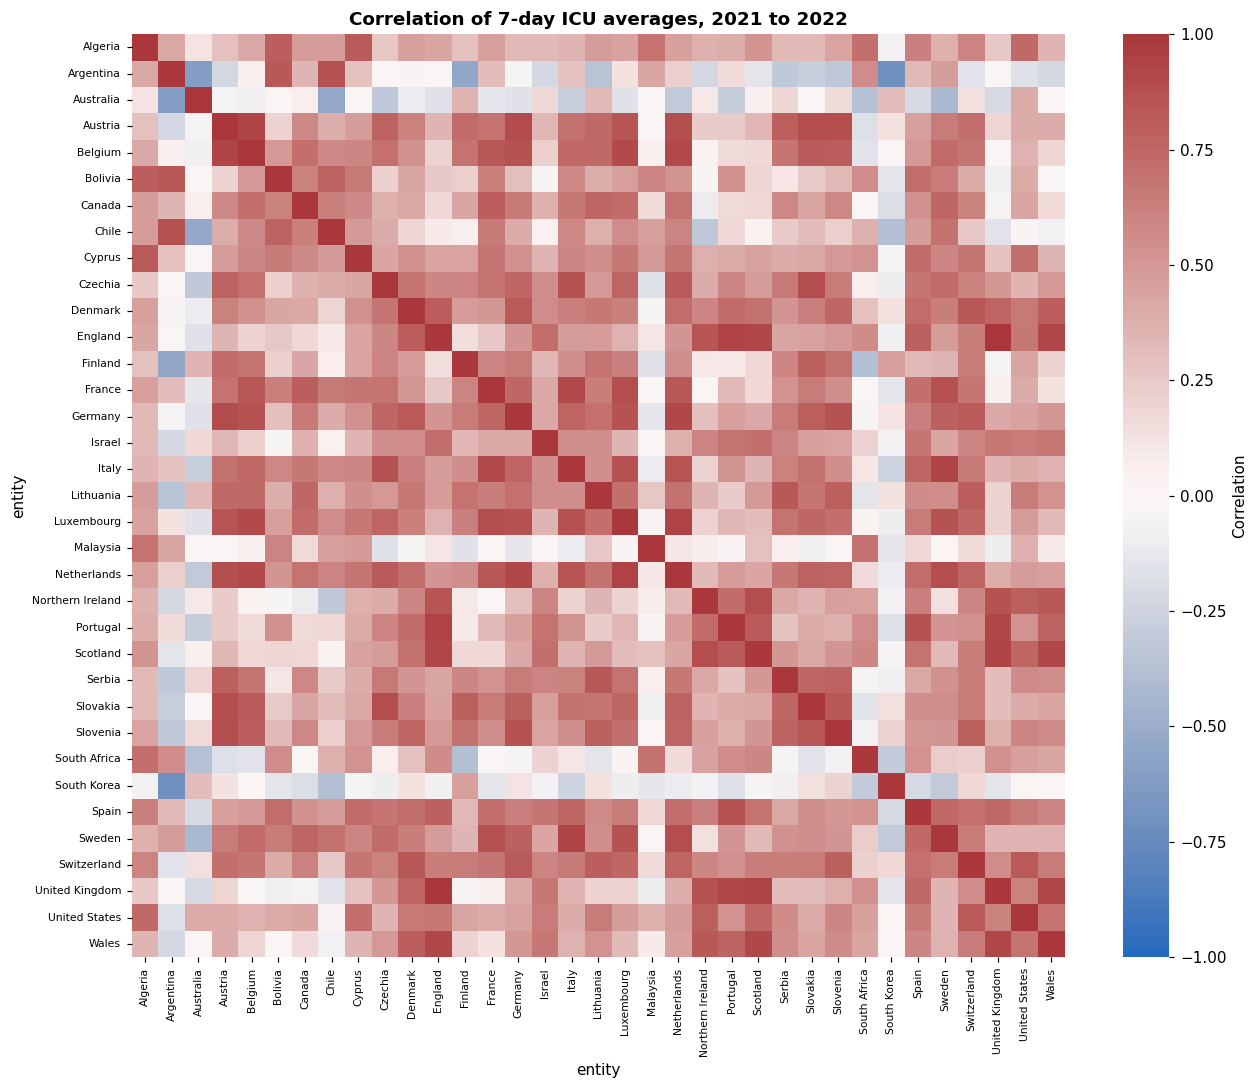

Countries in the comparison: 35


In [18]:
per = icu[icu.date.dt.year.isin([2021, 2022])]
full = []
for c, g in per.groupby("entity"):
    if len(g) / 730 >= 0.6:
        full.append(c)
pv = (icu[icu.entity.isin(full) & icu.date.dt.year.isin([2021, 2022])]
      .pivot_table(index="date", columns="entity", values="icu"))
pv = pv.asfreq("D").interpolate(limit=7).rolling(7, min_periods=4, center=True).mean()
corr = pv.corr(min_periods=200)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True,
            cbar_kws={"label": "Correlation"})
ax.set_title("Correlation of 7-day ICU averages, 2021 to 2022")
ax.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig(FIG + "16_icu_correlation.png"); plt.show()

print("Countries in the comparison:", len(corr))


## 17. When did each country's series end?

Most series end in 2023. Only Czechia, Italy and Malaysia report into August 2024. The dashed line marks 13 August 2024, the date the metadata gives for the last update. Series that end early can make a country look like it had no ICU patients in later years, when it may simply have stopped reporting.

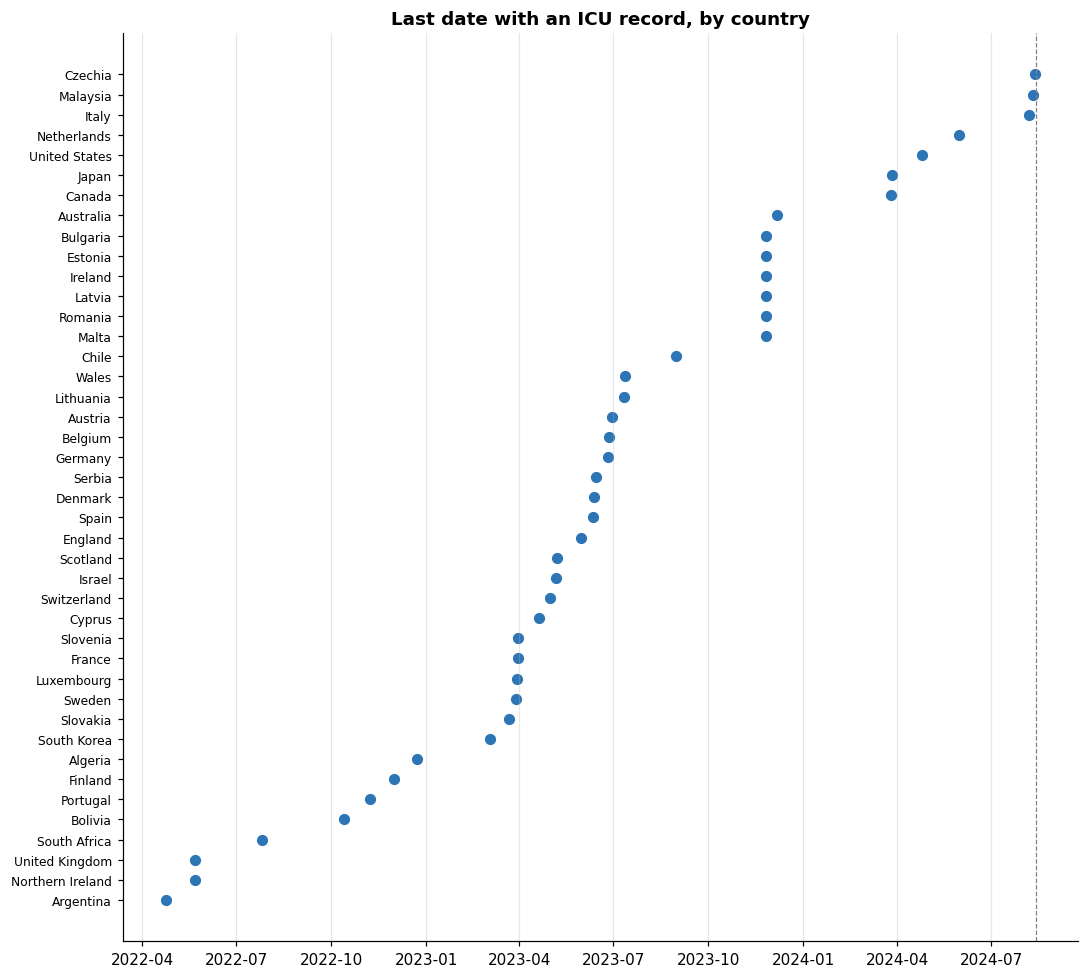

Countries whose last record is before 2023: 8 of 42
Countries with a record after 2023: 34


In [19]:
end = icu.groupby("entity")["date"].max().sort_values()

fig, ax = plt.subplots(figsize=(10, 9))
ax.scatter(end.values, end.index, s=40, color="#2e75b6")
ax.axvline(pd.Timestamp("2024-08-13"), color="grey", linestyle="--", linewidth=0.8)
ax.set_title("Last date with an ICU record, by country")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig(FIG + "17_series_end.png"); plt.show()

print("Countries whose last record is before 2023:", (end < "2023-01-01").sum(), "of", len(end))
print("Countries with a record after 2023:", (end >= "2023-01-01").sum())


## 18. Summary of findings

**What the data shows**

- The highest single-day ICU count in this file is 28,891 patients in the United States, on 12 January 2021. The US record has 1,381 days, one of the longer series here.
- Peak timing varies. The main ICU peak ranges from late March 2020 in Estonia to early April 2022 in South Korea (section 6). Countries with many reporting days show four to six separate waves (section 5).
- Reporting thins out quickly. In January 2022, 42 countries reported. In August 2024, only Czechia, Italy and Malaysia still did (section 4). Global totals built from these data would be incomplete for the later years.
- In 36 of 38 countries that reported in both periods, average ICU counts were lower in 2022 and 2023 than in 2020 and 2021. The median ratio is 0.34. South Korea (2.18) and Australia (1.63) were the exceptions (section 8). The drop fits lower infection pressure, better treatment and vaccination, but this data cannot separate those effects from changes in reporting.
- Weekend counts sit very close to weekday counts. The median weekend-to-weekday ratio is 0.99 across 36 countries (section 9). Weekend effects are small here.
- Zero values are common in some series. In Malta, 39 percent of records are zero, which most likely reflects missing reports entered as zero (section 10).
- Case counts and ICU counts move together with little delay. In 12 of 38 countries the best lag is zero days, and 19 of 38 have a best lag of three days or less. Only one country's best lag reached 14 days. The correlation is moderate, with a median of 0.40, and 16 countries fall below 0.30 (section 13). The one to two week delay often expected between infections and ICU admissions is hard to see in this data.
- In 23 of 38 countries the ICU peak came after the nearby case peak. The median gap is 10 days, and the spread is wide, from minus 120 to plus 65 days. Algeria's value sits at the edge of the 120-day search window, so treat it as unreliable (section 14).
- The severity ratio in section 15 is not a valid severity measure in this data. Sweden shows about 1,000 ICU patients for every 1,000 daily cases, which points to case counts that understate infections at that time. The ratio mostly reflects how cases were counted.

**What the data cannot show**

- No population column is included, so counts cannot be compared per person without outside data.
- The series ends in August 2024. Any statement about current hospital pressure would need newer data.
- ICU definitions vary. The metadata notes that some countries report ventilated or critically ill patients instead. Cross-country comparisons therefore mix definitions.
- Results in sections 13 to 15 describe this dataset only. They are not clinical measurements.

**Suggested next steps**

Add the OWID population file to compare countries per 100,000 people. Check the national sources listed in the metadata for any country with long gaps or many zeros. Repeat the lag analysis with the hospital admissions series from the same collection, which may give a cleaner timing signal than ICU counts.